In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BG_COLOR = "#0f0f0f"        
AXIS_COLOR = "#1a1a1a"     
TEXT_COLOR = "#e0e0e0"      
GOLD_COLOR = "#c5a059"     
MUTED_RED = "#a94442"  

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['figure.facecolor'] = BG_COLOR
plt.rcParams['axes.facecolor'] = AXIS_COLOR
plt.rcParams['text.color'] = TEXT_COLOR
plt.rcParams['axes.labelcolor'] = TEXT_COLOR
plt.rcParams['xtick.color'] = TEXT_COLOR
plt.rcParams['ytick.color'] = TEXT_COLOR
plt.rcParams['axes.edgecolor'] = "#333333"

print("Environment setup completed with custom dark & muted gold theme.")

Environment setup completed with custom dark & muted gold theme.


In [3]:
df = pd.read_csv('titanic.csv')
display(df.head())
print(df.shape)
df.info()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


(891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [4]:
print(df.isnull().sum())

df['Age'] = df['Age'].fillna(df['Age'].median())

if 'Embarked' in df.columns:
    df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

if 'Cabin' in df.columns:
    df.drop(columns=['Cabin'], inplace=True)

print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


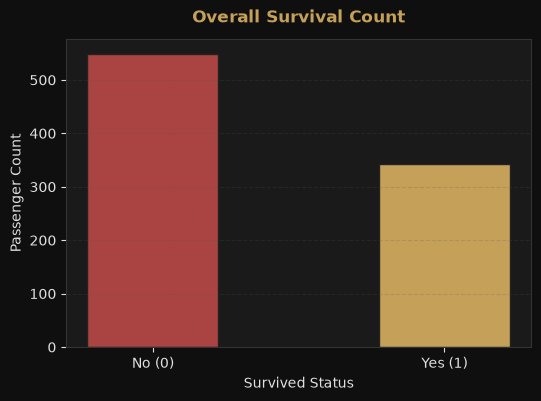

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
survived_counts = df['Survived'].value_counts().sort_index()

ax.bar(['No (0)', 'Yes (1)'], survived_counts, color=[MUTED_RED, GOLD_COLOR], width=0.45, edgecolor="#222222")
ax.set_title('Overall Survival Count', color=GOLD_COLOR, fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Survived Status')
ax.set_ylabel('Passenger Count')
ax.grid(axis='y', linestyle='--', alpha=0.2, color='#555555')

plt.show()

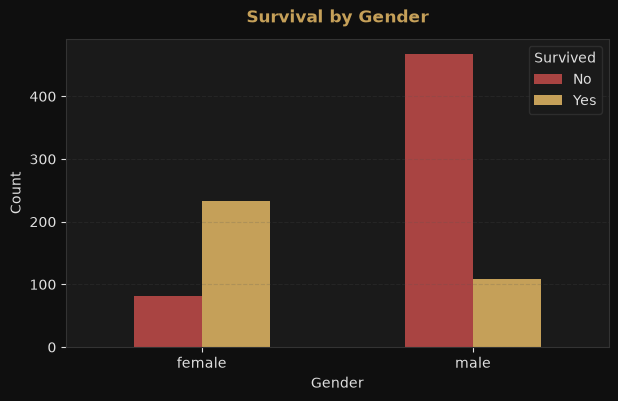

In [6]:
survived_by_sex = pd.crosstab(df['Sex'], df['Survived'])
ax = survived_by_sex.plot(kind='bar', stacked=False, color=[MUTED_RED, GOLD_COLOR], figsize=(7, 4))

fig = plt.gcf()
fig.patch.set_facecolor(BG_COLOR)
ax.set_title('Survival by Gender', color=GOLD_COLOR, fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Gender')
ax.set_ylabel('Count')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(['No', 'Yes'], title='Survived', facecolor=AXIS_COLOR, edgecolor='#333333', labelcolor=TEXT_COLOR)
ax.grid(axis='y', linestyle='--', alpha=0.2, color='#555555')

plt.show()

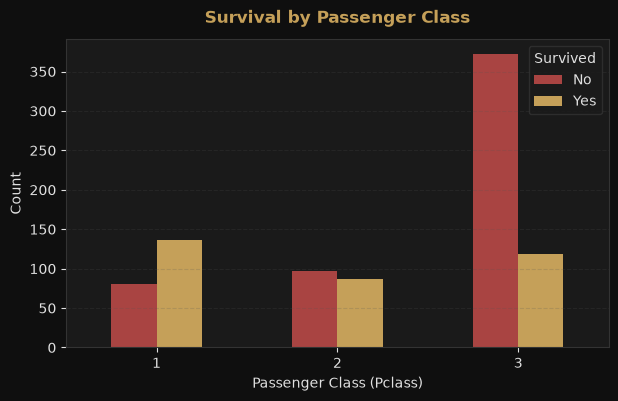

In [7]:
survived_by_class = pd.crosstab(df['Pclass'], df['Survived'])
ax = survived_by_class.plot(kind='bar', color=[MUTED_RED, GOLD_COLOR], figsize=(7, 4))

fig = plt.gcf()
fig.patch.set_facecolor(BG_COLOR)
ax.set_title('Survival by Passenger Class', color=GOLD_COLOR, fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Passenger Class (Pclass)')
ax.set_ylabel('Count')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(['No', 'Yes'], title='Survived', facecolor=AXIS_COLOR, edgecolor='#333333', labelcolor=TEXT_COLOR)
ax.grid(axis='y', linestyle='--', alpha=0.2, color='#555555')

plt.show()

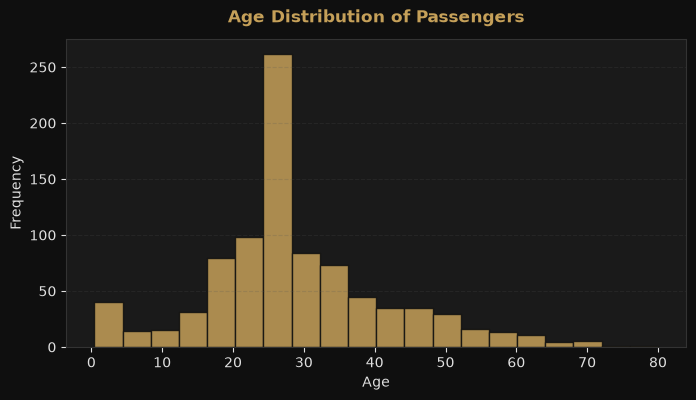

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
fig.patch.set_facecolor(BG_COLOR)

ax.hist(df['Age'].dropna(), bins=20, color=GOLD_COLOR, edgecolor='#0f0f0f', alpha=0.85)
ax.set_title('Age Distribution of Passengers', color=GOLD_COLOR, fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Age')
ax.set_ylabel('Frequency')
ax.grid(axis='y', linestyle='--', alpha=0.2, color='#555555')

plt.show()